# 02 · Forest baseline and post-2020 loss for every plot

Two questions per plot:

| Question | Dataset | Resolution |
|---|---|---|
| Was it forest on 31 Dec 2020? | **JRC Global Forest Cover 2020 (V4)**, the EU reference map for EUDR | 10 m |
| Was tree cover lost in 2021 or later? | **Hansen/UMD Global Forest Change v1.13** (loss up to 2025) | 30 m |

Only the pixels around each plot are read over HTTP, so the whole run takes well under a minute.

**Flags**
- `low_risk`: no tree-cover loss after 2020 above the screening threshold
- `review`: loss after 2020 **and** JRC mapped forest in 2020 → both datasets agree
- `review_data_conflict`: loss after 2020 but JRC mapped (almost) no forest → datasets disagree (often tree crops / agroforestry); check imagery

⚠️ Screening only, not a legal compliance determination. Demo plots are **synthetic**.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from eudr_screen import screen

plots = gpd.read_file(ROOT / "data" / "demo_plots.geojson")
print(len(plots), "plots;", plots.geometry.geom_type.value_counts().to_dict())

20 plots; {'Point': 11, 'Polygon': 9}


## Run the screening

In [2]:
%%time
res = screen.screen(plots)
cols = ["plot_id", "geom_input", "area_ha", "jrc_forest_2020_share", "treecover2000_mean",
        "loss_post2020_ha", "loss_years", "flag"]
res[cols].round(2)

CPU times: user 382 ms, sys: 165 ms, total: 547 ms
Wall time: 27.2 s


,plot_id,geom_input,area_ha,jrc_forest_2020_share,treecover2000_mean,loss_post2020_ha,loss_years,flag
0,DEMO-001,point,2.5,0.47,54.66,2.11,"2024,2025",review
1,DEMO-002,polygon,6.2,0.82,71.95,2.37,"2024,2025",review
2,DEMO-003,point,2.5,0.00,51.69,0.94,"2022,2024,2025",review_data_conflict
3,DEMO-004,polygon,6.2,0.10,57.13,2.85,"2022,2023,2024",review_data_conflict
4,DEMO-005,point,2.5,0.00,56.72,1.33,"2021,2022",review_data_conflict
5,DEMO-006,polygon,6.2,0.00,51.18,1.78,"2021,2022",review_data_conflict
6,DEMO-007,point,2.5,1.00,72.66,1.01,2023,review
7,DEMO-008,point,2.5,0.00,54.81,0.00,,low_risk
8,DEMO-009,polygon,6.2,0.00,68.59,0.00,,low_risk
9,DEMO-010,point,2.5,0.00,35.44,0.00,,low_risk


## Check against the known answers
The demo plots were placed with an expected case, so we can measure whether the tool gets them right.

In [3]:
ct = pd.crosstab(res.expected_case, res.flag)
should_flag = res.expected_case == "post2020_loss"
flagged = res.flag != screen.FLAG_LOW
print(f"Post-2020 loss plots caught: {(should_flag & flagged).sum()} / {should_flag.sum()}")
print(f"False alarms:                {(~should_flag & flagged).sum()} / {(~should_flag).sum()}")
ct

Post-2020 loss plots caught: 7 / 7
False alarms:                0 / 13


flag,low_risk,review,review_data_conflict
expected_case,,,
no_forest,5,0,0
post2020_loss,0,3,4
pre2020_loss,4,0,0
stable_forest,4,0,0


## Why each plot got its flag

In [4]:
pd.set_option("display.max_colwidth", 200)
res[["plot_id", "flag", "flag_reason"]]

,plot_id,flag,flag_reason
0,DEMO-001,review,"2.11 ha tree-cover loss after 2020 (2024,2025); JRC maps 47% of plot as forest in 2020."
1,DEMO-002,review,"2.37 ha tree-cover loss after 2020 (2024,2025); JRC maps 82% of plot as forest in 2020."
2,DEMO-003,review_data_conflict,"0.94 ha tree-cover loss after 2020 (2022,2024,2025), but JRC 2020 maps only 0% as forest (possible tree crop / agroforestry). Datasets disagree: check imagery."
3,DEMO-004,review_data_conflict,"2.85 ha tree-cover loss after 2020 (2022,2023,2024), but JRC 2020 maps only 10% as forest (possible tree crop / agroforestry). Datasets disagree: check imagery."
4,DEMO-005,review_data_conflict,"1.33 ha tree-cover loss after 2020 (2021,2022), but JRC 2020 maps only 0% as forest (possible tree crop / agroforestry). Datasets disagree: check imagery."
5,DEMO-006,review_data_conflict,"1.78 ha tree-cover loss after 2020 (2021,2022), but JRC 2020 maps only 0% as forest (possible tree crop / agroforestry). Datasets disagree: check imagery."
6,DEMO-007,review,1.01 ha tree-cover loss after 2020 (2023); JRC maps 100% of plot as forest in 2020.
7,DEMO-008,low_risk,No tree-cover loss after 2020.
8,DEMO-009,low_risk,No tree-cover loss after 2020.
9,DEMO-010,low_risk,No tree-cover loss after 2020.


## Overview map

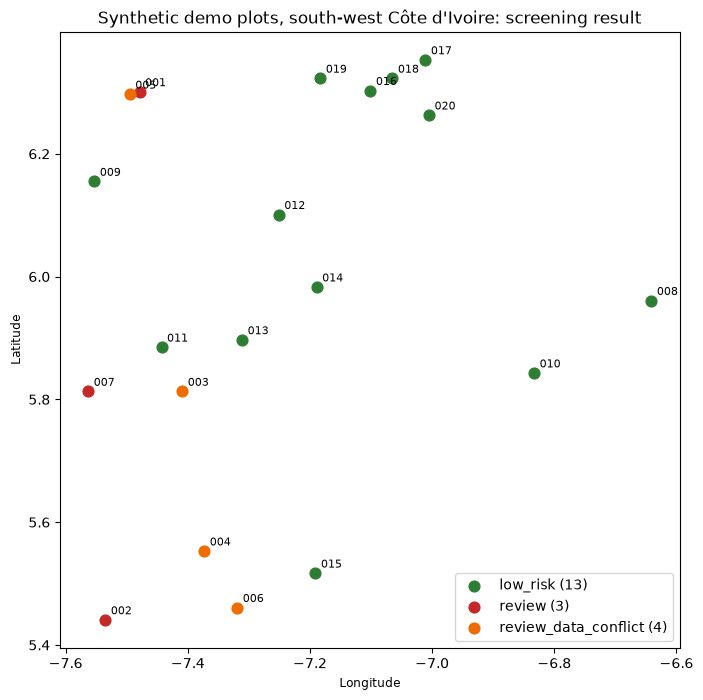

In [5]:
colors = {screen.FLAG_LOW: "#2e7d32", screen.FLAG_REVIEW: "#c62828", screen.FLAG_CONFLICT: "#ef6c00"}
fig, ax = plt.subplots(figsize=(8, 8))
for flag, sub in res.groupby("flag"):
    sub.centroid.plot(ax=ax, color=colors[flag], markersize=60, label=f"{flag} ({len(sub)})")
for _, r in res.iterrows():
    ax.annotate(r.plot_id.replace("DEMO-", ""), (r.geometry.centroid.x, r.geometry.centroid.y),
                xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title("Synthetic demo plots, south-west Côte d'Ivoire: screening result")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend()
fig.savefig(ROOT / "outputs" / "screening_overview.png", dpi=120, bbox_inches="tight")

## Export

In [6]:
out = ROOT / "outputs"
out.mkdir(exist_ok=True)
res.to_file(out / "screening_results.geojson", driver="GeoJSON")
res.drop(columns="geometry").to_csv(out / "screening_results.csv", index=False)
sorted(p.name for p in out.iterdir())

['DEMO-001_before_after.png',
 'screening_overview.png',
 'screening_results.csv',
 'screening_results.geojson']

## Limitations
- **Thresholds** (0.2 ha or 5 % of plot) filter single-pixel noise. EUDR itself has no minimum area, so small losses are still reported in `flag_reason`.
- **Hansen loss = tree-cover loss**, not legally defined deforestation: it also captures plantation harvest, fire and storm damage.
- **JRC 2020** excludes tree crops such as cocoa or rubber from "forest" by design, which explains most `review_data_conflict` cases here.
- Point plots are approximated as circles of the declared area; the real shape is unknown.
- Hansen v1.13 covers loss up to 2025; 2026 clearing is not yet in it. Sentinel-2 (notebook 01) can fill that gap.